Phase 1 — Data Loading, RFM Engineering & EDA

In [3]:
# ==========================================
# 1. DATA LOADING & CLEANING
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# 1. Load Dataset
file_path = "ecommerce_customer_behavior_dataset_v2.csv"
df = pd.read_csv(file_path)
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

print("=== 1. DATASET OVERVIEW ===")
print("Dataset Shape:", df.shape)
print("Unique Customers:", df['Customer_ID'].nunique())
print("Unique Orders:", df['Order_ID'].nunique())
print("Date Range:", df['Date'].min().date(), "to", df['Date'].max().date())

# 2. Data Quality Check & Cleaning
print("\n=== 2. DATA CLEANING ===")
print("Missing Values in essential columns:")
print(df[['Customer_ID', 'Order_ID', 'Date', 'Total_Amount']].isnull().sum())

before_rows = len(df)
duplicates = df.duplicated().sum()
df = df.drop_duplicates().copy()

print(f"Duplicate rows found and removed: {duplicates}")
print(f"Cleaned Dataset Shape: {df.shape}")

=== 1. DATASET OVERVIEW ===
Dataset Shape: (17049, 18)
Unique Customers: 5000
Unique Orders: 17049
Date Range: 2023-01-01 to 2024-03-25

=== 2. DATA CLEANING ===
Missing Values in essential columns:
Customer_ID     0
Order_ID        0
Date            0
Total_Amount    0
dtype: int64
Duplicate rows found and removed: 0
Cleaned Dataset Shape: (17049, 18)


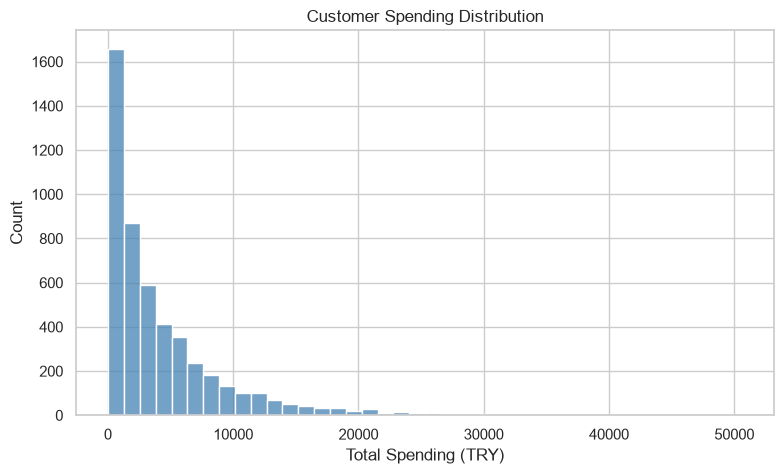

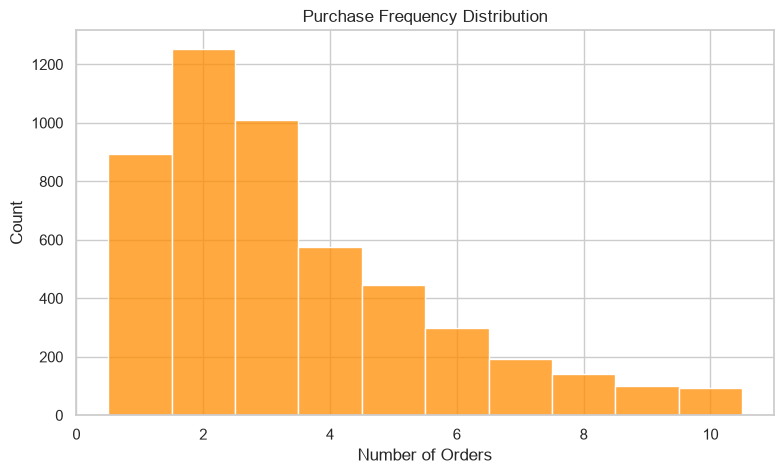

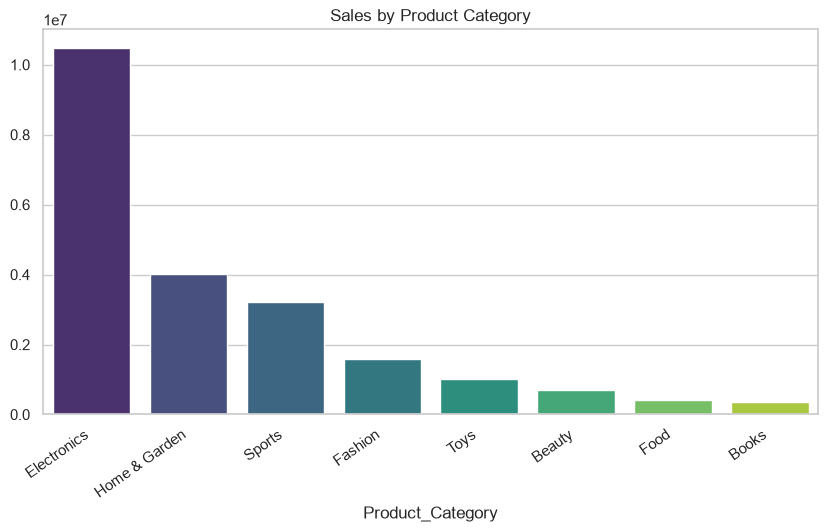

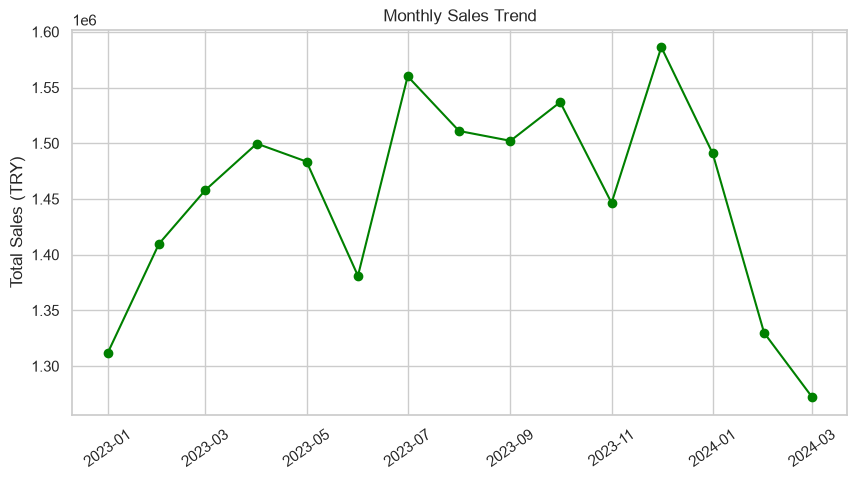

In [5]:
# ==========================================
# 2. EXPLORATORY DATA ANALYSIS
# ==========================================
# 1. Distribution of Total Customer Spending
customer_summary = df.groupby("Customer_ID").agg(
    Total_Spending=("Total_Amount", "sum"),
    Purchase_Frequency=("Order_ID", "nunique")
).reset_index()

plt.figure(figsize=(9, 5))
sns.histplot(customer_summary["Total_Spending"], bins=40, color="steelblue")
plt.title("Customer Spending Distribution")
plt.xlabel("Total Spending (TRY)")
plt.show()

# 2. Customer Purchase Frequency Distribution
plt.figure(figsize=(9, 5))
sns.histplot(customer_summary["Purchase_Frequency"], discrete=True, color="darkorange")
plt.title("Purchase Frequency Distribution")
plt.xlabel("Number of Orders")
plt.show()

# 3. Sales by Product Category
category_sales = df.groupby("Product_Category")["Total_Amount"].sum().sort_values(ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(x=category_sales.index, y=category_sales.values, hue=category_sales.index, palette="viridis", legend=False)
plt.title("Sales by Product Category")
plt.xticks(rotation=35, ha="right")
plt.show()

# 4. Monthly Sales Trend
monthly_sales = df.set_index("Date").resample("MS")["Total_Amount"].sum()
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o", color="green")
plt.title("Monthly Sales Trend")
plt.ylabel("Total Sales (TRY)")
plt.xticks(rotation=35)
plt.show()

In [2]:

# ==========================================
# 3. RFM FEATURE ENGINEERING
# ==========================================

# Set reference date to one day after
# the latest transaction date

reference_date = df['Date'].max() + pd.Timedelta(days=1)

print("Reference Date:", reference_date.date())

# Group transactions by Customer_ID
rfm = df.groupby('Customer_ID').agg(
    
    # Most recent purchase date
    Last_Purchase_Date=('Date', 'max'),

    # Count distinct orders
    Frequency=('Order_ID', 'nunique'),

    # Total customer spending
    Monetary=('Total_Amount', 'sum')
)

# Calculate Recency in days
rfm['Recency'] = (
    reference_date - rfm['Last_Purchase_Date']
).dt.days

# Remove intermediate date column
rfm = rfm.drop(columns=['Last_Purchase_Date'])

# Arrange columns in RFM order
rfm = rfm[['Recency', 'Frequency', 'Monetary']]

# ==========================================
# 4. DISPLAY RFM RESULTS
# ==========================================

print("\nFirst 5 Customers:")
print(rfm.head())

print("\nRFM DataFrame Shape:")
print(rfm.shape)

print("\nRFM Statistical Summary:")
print(rfm.describe())


Reference Date: 2024-03-26

First 5 Customers:
             Recency  Frequency  Monetary
Customer_ID                              
CUST_00001       112          3   2199.63
CUST_00002       284          2    809.90
CUST_00003        83          2   3030.81
CUST_00004        42          1    383.22
CUST_00005       279          3   2422.73

RFM DataFrame Shape:
(5000, 3)

RFM Statistical Summary:
           Recency    Frequency      Monetary
count  5000.000000  5000.000000   5000.000000
mean    125.716400     3.409800   4355.810518
std     108.050972     2.181746   5274.546636
min       1.000000     1.000000     14.280000
25%      39.000000     2.000000    889.410000
50%      94.000000     3.000000   2493.925000
75%     185.000000     5.000000   5796.297500
max     450.000000    10.000000  50628.150000


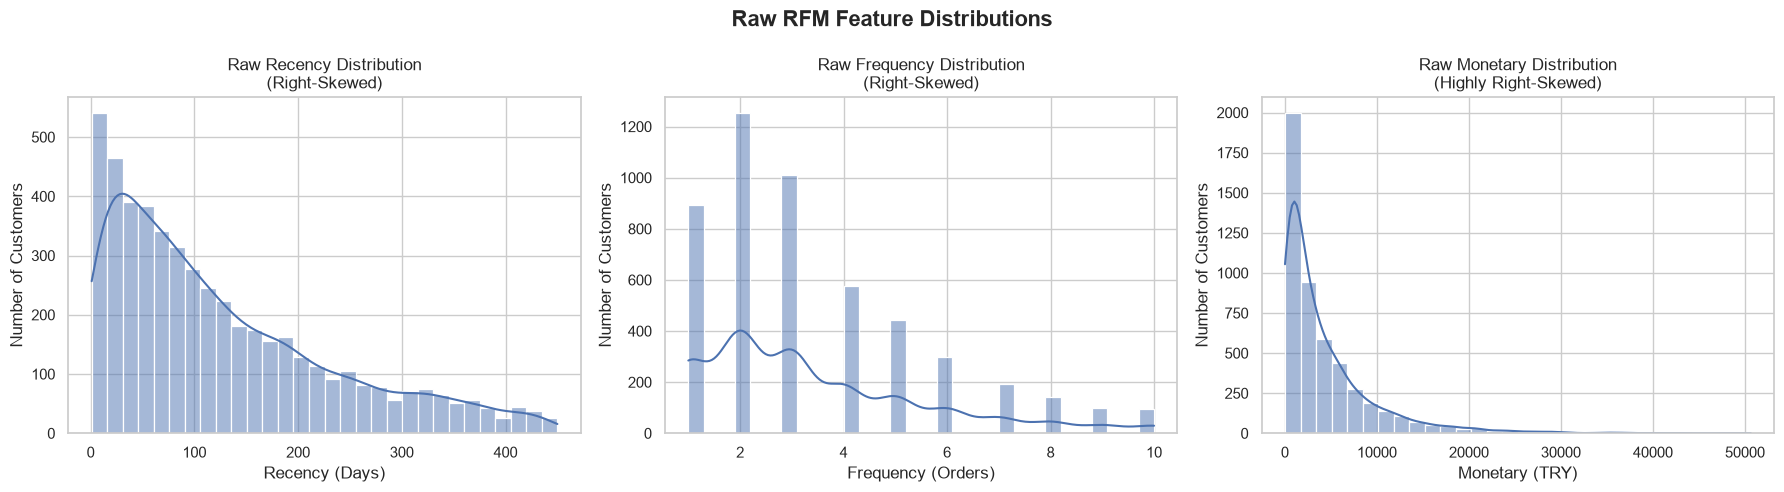


Raw RFM Skewness:
Recency      1.025482
Frequency    1.113005
Monetary     2.549442
dtype: float64


In [3]:

# ==========================================
# 5. RAW RFM DISTRIBUTIONS
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Recency distribution
sns.histplot(
    rfm['Recency'],
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title(
    'Raw Recency Distribution\n(Right-Skewed)'
)
axes[0].set_xlabel('Recency (Days)')
axes[0].set_ylabel('Number of Customers')

# Frequency distribution
sns.histplot(
    rfm['Frequency'],
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title(
    'Raw Frequency Distribution\n(Right-Skewed)'
)
axes[1].set_xlabel('Frequency (Orders)')
axes[1].set_ylabel('Number of Customers')

# Monetary distribution
sns.histplot(
    rfm['Monetary'],
    bins=30,
    kde=True,
    ax=axes[2]
)
axes[2].set_title(
    'Raw Monetary Distribution\n(Highly Right-Skewed)'
)
axes[2].set_xlabel('Monetary (TRY)')
axes[2].set_ylabel('Number of Customers')

plt.suptitle(
    'Raw RFM Feature Distributions',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

# Calculate skewness numerically
print("\nRaw RFM Skewness:")
print(rfm.skew())


In [4]:

# ==========================================
# 6. LOG TRANSFORMATION
# ==========================================

rfm_log = np.log1p(rfm)

print("Log-transformed RFM:")
print(rfm_log.head())

# ==========================================
# 7. STANDARDIZATION
# ==========================================

scaler = StandardScaler()

rfm_scaled = pd.DataFrame(
    scaler.fit_transform(rfm_log),
    columns=rfm_log.columns,
    index=rfm_log.index
)

print("\nScaled RFM DataFrame:")
print(rfm_scaled.head())

print("\nScaled DataFrame Shape:")
print(rfm_scaled.shape)

# Verify mean and standard deviation
print("\nFeature Means:")
print(rfm_scaled.mean())

print("\nFeature Standard Deviations:")
print(rfm_scaled.std())


Log-transformed RFM:
              Recency  Frequency  Monetary
Customer_ID                               
CUST_00001   4.727388   1.386294  7.696499
CUST_00002   5.652489   1.098612  6.698145
CUST_00003   4.430817   1.098612  8.016915
CUST_00004   3.761200   0.693147  5.951215
CUST_00005   5.634790   1.386294  7.793063

Scaled RFM DataFrame:
              Recency  Frequency  Monetary
Customer_ID                               
CUST_00001   0.323613   0.029862  0.030487
CUST_00002   1.134660  -0.585980 -0.703359
CUST_00003   0.063606  -0.585980  0.266011
CUST_00004  -0.523454  -1.453959 -1.252394
CUST_00005   1.119142   0.029862  0.101467

Scaled DataFrame Shape:
(5000, 3)

Feature Means:
Recency      9.379164e-17
Frequency    3.957723e-16
Monetary     3.467449e-16
dtype: float64

Feature Standard Deviations:
Recency      1.0001
Frequency    1.0001
Monetary     1.0001
dtype: float64


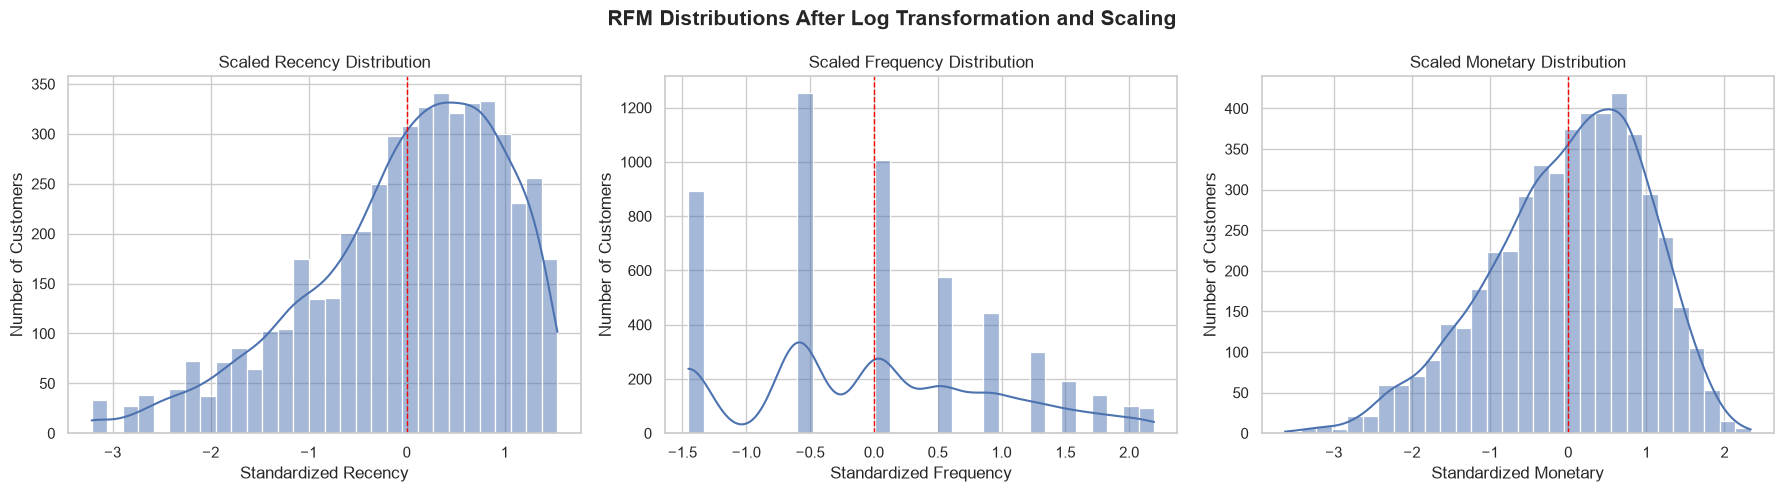

In [5]:

# ==========================================
# 8. TRANSFORMED RFM DISTRIBUTIONS
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

features = ['Recency', 'Frequency', 'Monetary']

for i, feature in enumerate(features):

    sns.histplot(
        rfm_scaled[feature],
        bins=30,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(
        f'Scaled {feature} Distribution'
    )

    axes[i].set_xlabel(
        f'Standardized {feature}'
    )

    axes[i].set_ylabel('Number of Customers')

    # Reference line at zero
    axes[i].axvline(
        0,
        color='red',
        linestyle='--',
        linewidth=1
    )

plt.suptitle(
    'RFM Distributions After Log Transformation and Scaling',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()
